In [17]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk

search = lk.search_lightcurve(
    "TIC 428919267",
    mission="TESS",
    sector=91,
    author="SPOC",
    exptime=20
)

lc = search.download(
    quality_bitmask="default"
)

lc_clean = lc.remove_nans().normalize()

In [18]:
lc_clean = lc_clean.remove_outliers(
    sigma_upper=5,
    sigma_lower=10
)

In [19]:
t_tess = lc_clean.time.value
flux_tess = lc_clean.flux.value
flux_err_tess = lc_clean.flux_err.value

bjd_tess = t_tess + 2457000

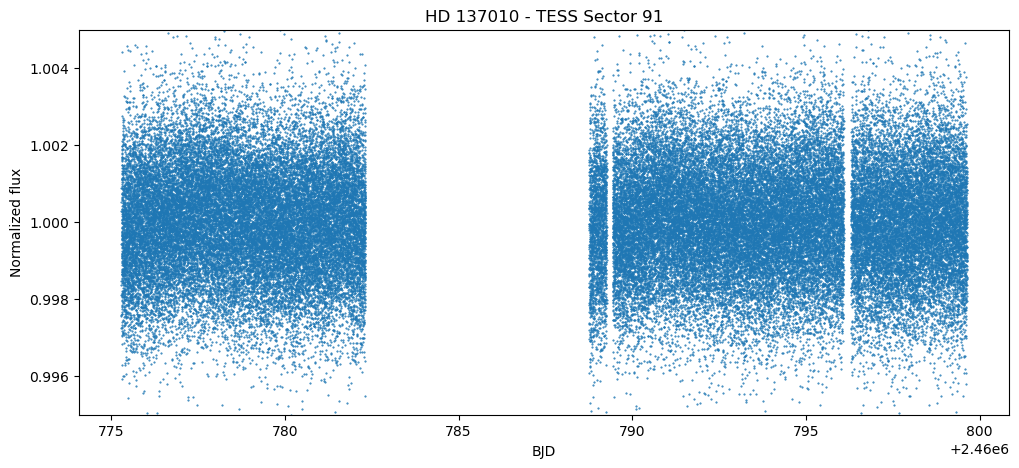

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    bjd_tess,
    flux_tess,
    ".",
    markersize=1
)

plt.xlabel("BJD")
plt.ylabel("Normalized flux")
plt.title("HD 137010 - TESS Sector 91")

plt.ylim(0.995, 1.005)

plt.show()

C:\Users\Sophia Kugler\AppData\Local\Temp\ipykernel_42408\3957500842.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


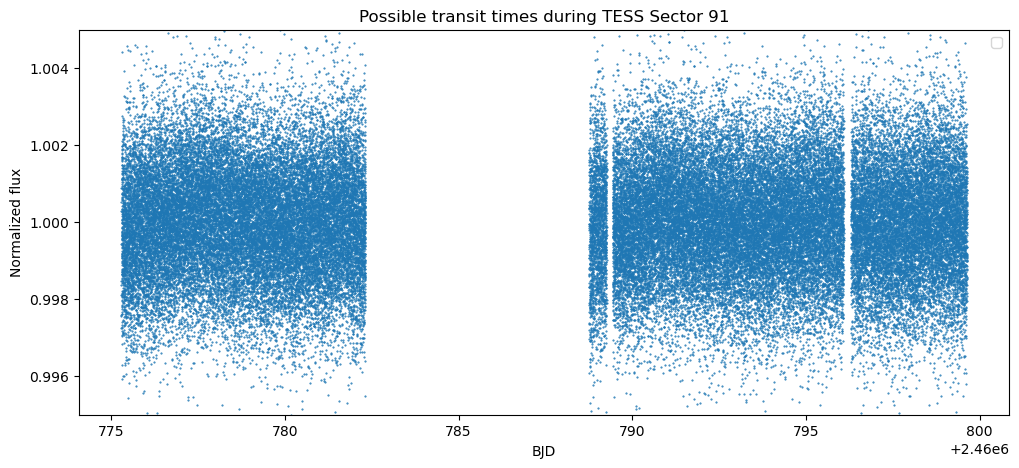

In [23]:
t0 = 2458055.0969

periods = [300, 320, 340, 355, 380, 400]

plt.figure(figsize=(12, 5))
plt.plot(bjd_tess, flux_tess, ".", markersize=1)

for P in periods:
    for n in range(1, 15):
        t_pred = t0 + n*P

        if bjd_tess.min() < t_pred < bjd_tess.max():
            plt.axvline(
                t_pred,
                linestyle="--",
                label=f"P = {P} d"
            )

plt.xlabel("BJD")
plt.ylabel("Normalized flux")
plt.title("Possible transit times during TESS Sector 91")
plt.ylim(0.995, 1.005)
plt.legend()
plt.show()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

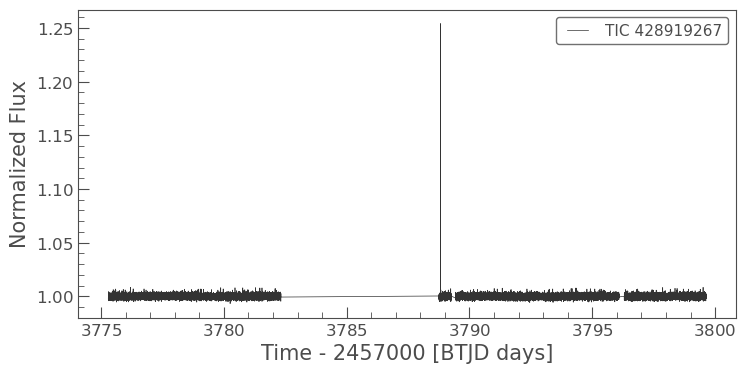

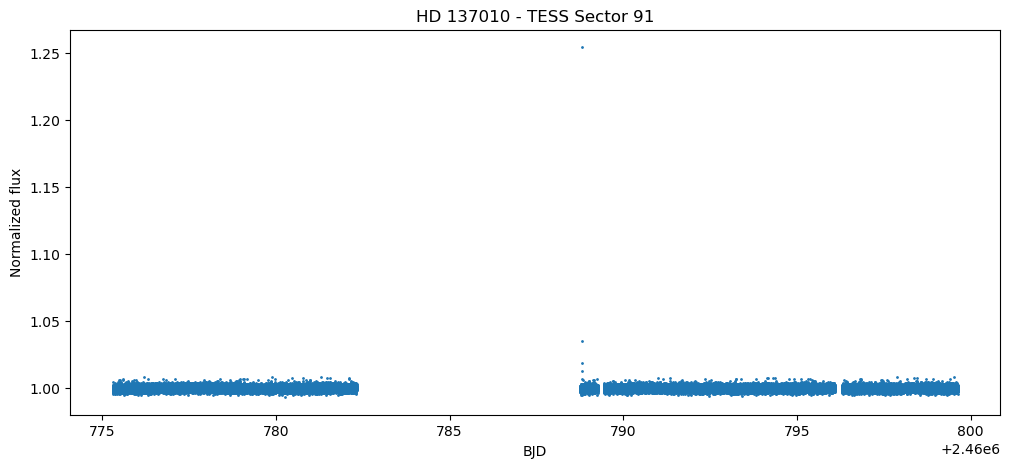

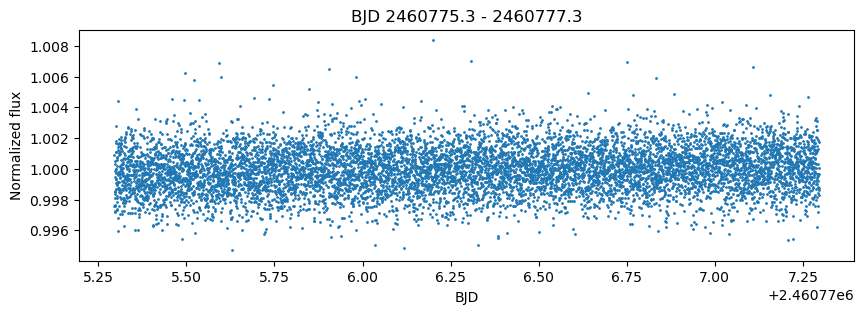

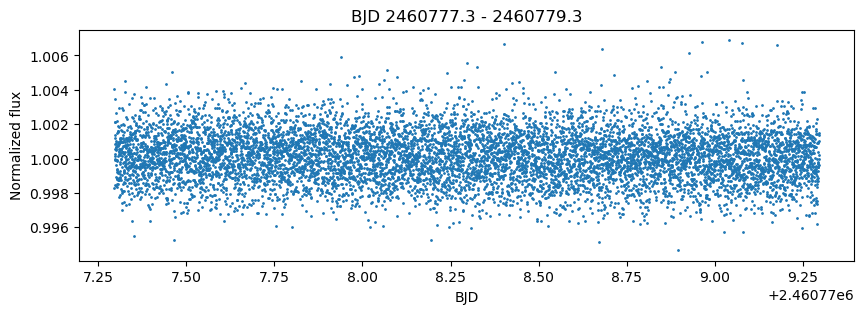

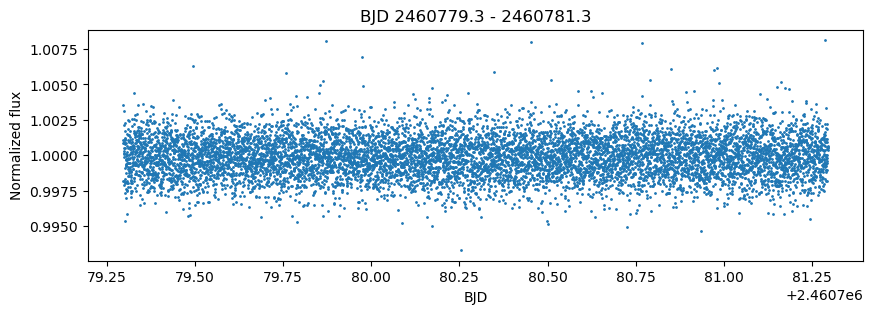

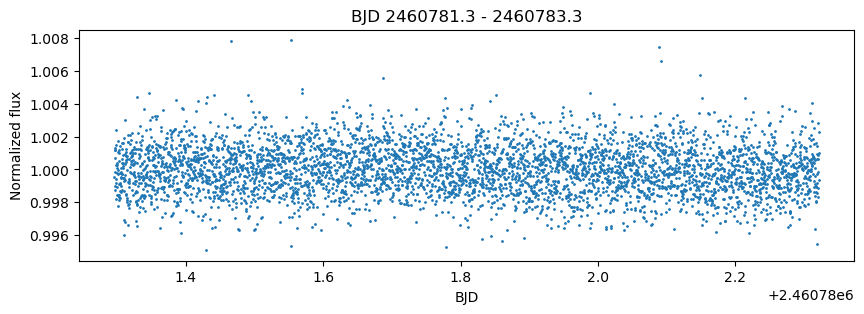

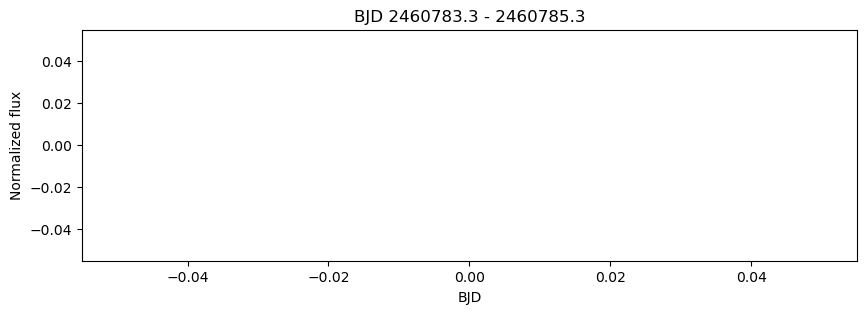

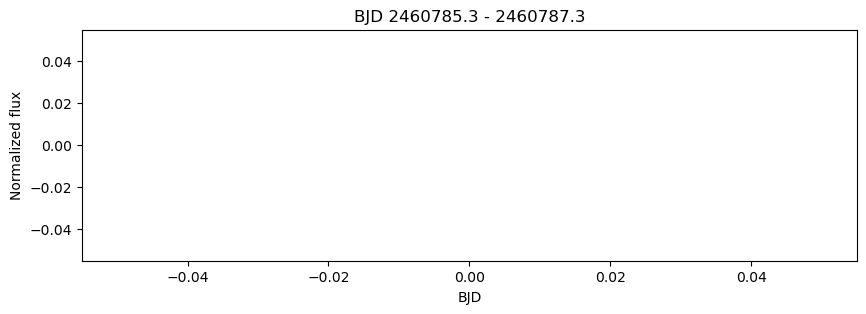

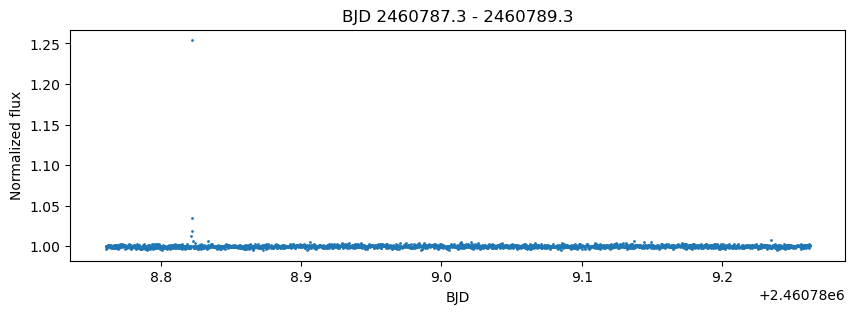

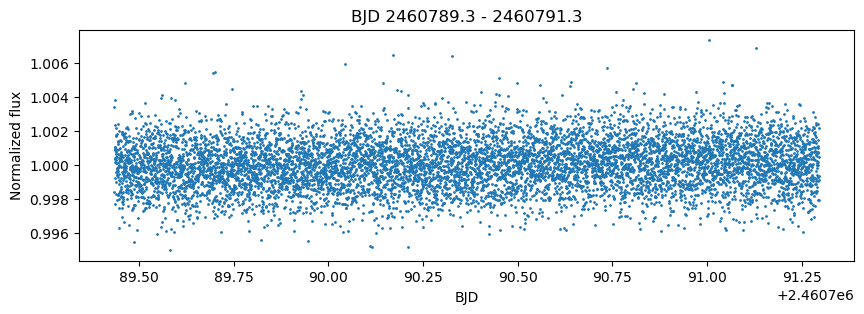

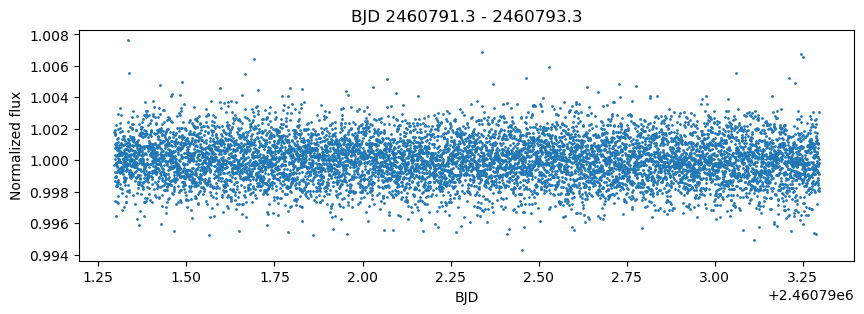

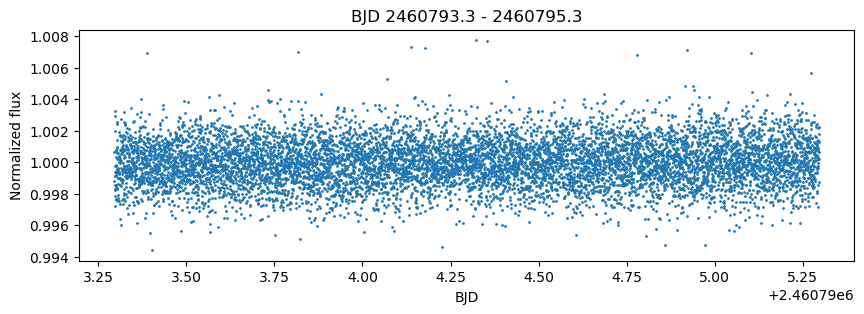

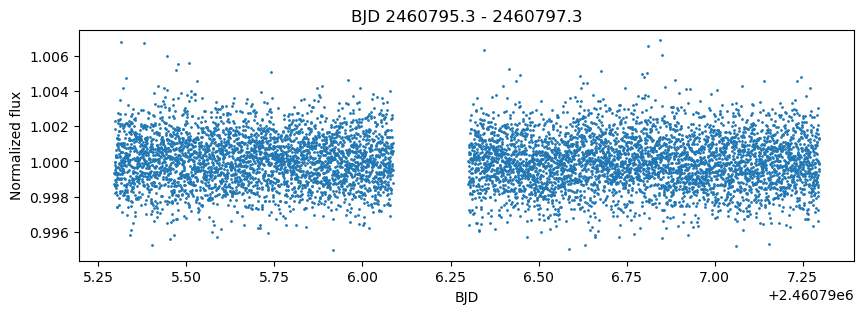

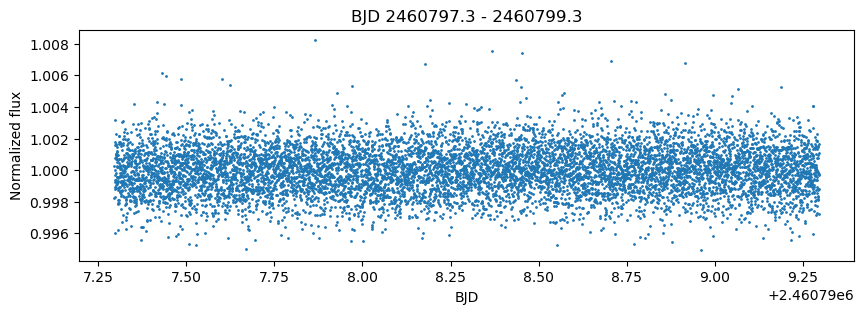

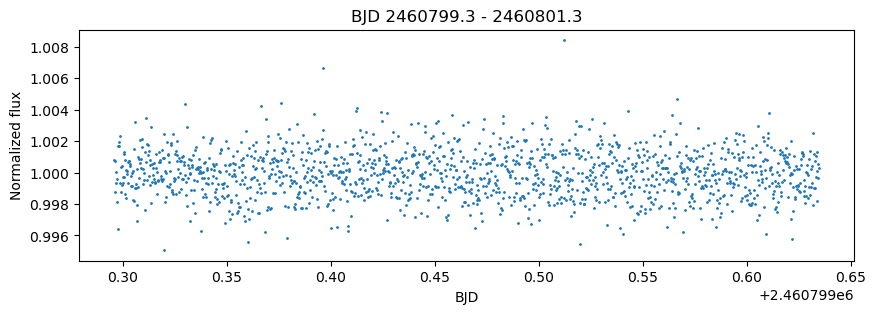

In [13]:
window = 2.0

start = np.min(bjd_tess)
end = np.max(bjd_tess)

current = start

while current < end:

    mask = (
        (bjd_tess >= current) &
        (bjd_tess < current + window)
    )

    plt.figure(figsize=(10, 3))

    plt.plot(
        bjd_tess[mask],
        flux_tess[mask],
        ".",
        markersize=2
    )

    plt.xlabel("BJD")
    plt.ylabel("Normalized flux")
    plt.title(f"BJD {current:.1f} - {current + window:.1f}")

    plt.show()

    current += window

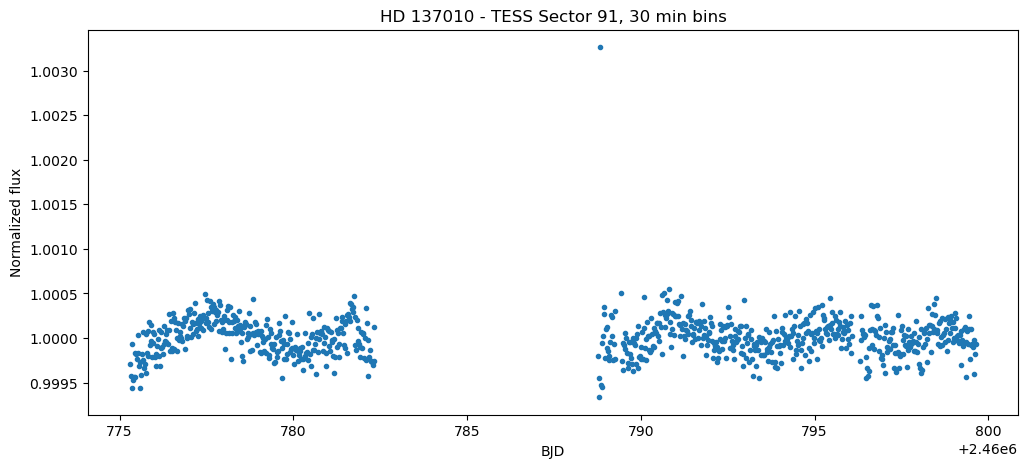

In [14]:
lc_30min = lc_clean.bin(time_bin_size=30/1440)
plt.figure(figsize=(12, 5))

plt.plot(
    lc_30min.time.value + 2457000,
    lc_30min.flux.value,
    "."
)

plt.xlabel("BJD")
plt.ylabel("Normalized flux")
plt.title("HD 137010 - TESS Sector 91, 30 min bins")

plt.show()

In [15]:
t0 = 2458055.0969
P = 355.0

n = np.arange(1, 20)

predicted_transits = t0 + n * P

predicted_transits

in_tess = predicted_transits[
    (predicted_transits >= np.min(bjd_tess)) &
    (predicted_transits <= np.max(bjd_tess))
]

print(in_tess)

[]


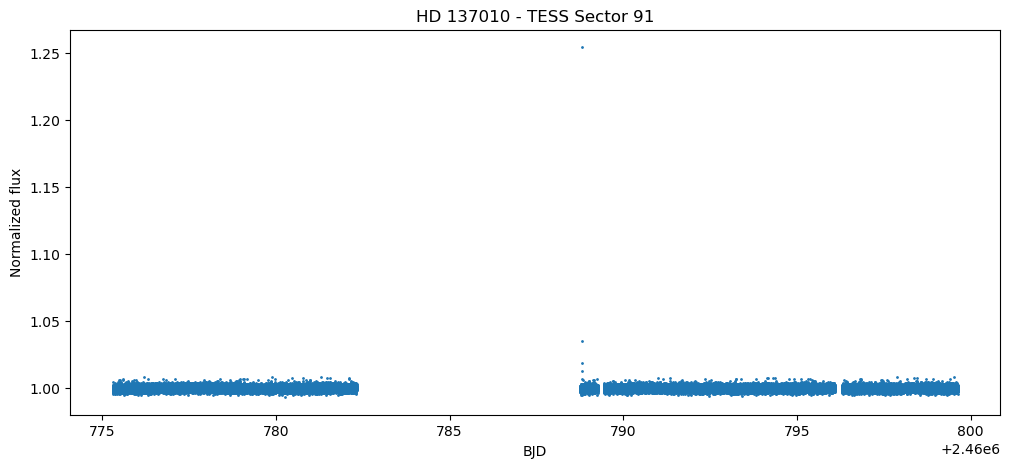

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    bjd_tess,
    flux_tess,
    ".",
    markersize=2
)

for transit_time in in_tess:
    plt.axvline(
        transit_time,
        linestyle="--",
        label=f"P = 355 d prediction"
    )

plt.xlabel("BJD")
plt.ylabel("Normalized flux")
plt.title("HD 137010 - TESS Sector 91")

plt.show()